# Lesson 08 · Mixture models and expectation-maximization

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 9 (pp. 75–88)

**Question:** Suppose we didn't know who the pitchers were. Could batting records alone separate pitchers from everyone else, and how should we shrink a player when we don't know which group he belongs to?

**Goal:** Fit a two-component beta-binomial mixture with an EM algorithm written from scratch, assign players to clusters with posterior probabilities, and shrink with a mixture prior.

**Contents**

1. Setup: pitchers back in
2. One beta doesn't fit
3. A beta-binomial fitting function
4. EM by hand: maximize, expect, repeat
5. Posterior cluster probabilities
6. How well did it find the pitchers?
7. Shrinkage with a mixture
8. Exercises

**Tags:** `mixture-models` `expectation-maximization` `clustering` `beta-binomial` `posterior-probability` `shrinkage`

**Before you start:** Lessons 02 and 06.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [2]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

# National League players since 1980, pitchers included (flagged in is_pitcher)
career = eb_data.career_with_pitchers(league="NL", since=1980)
print(f"{len(career):,} players, {career['is_pitcher'].mean():.0%} pitchers")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
6,193 players, 44% pitchers


## 1. Setup

We'll fit only on players with **at least 20 at-bats**. Keep `is_pitcher` aside: the algorithm must not see it. We use it only to grade the result at the end.

**8.1.1 · Your turn.** Make `fit_data = career[career.AB >= 20]`.

In [3]:
# 8.1.1 · Your code here
fit_data = career[career.AB >= 20].copy()
fit_data.head()

,playerID,name,H,AB,average,year,is_pitcher
5,abbotje01,Jeff Abbott,11,42,0.2619,2001.0,False
6,abbotji01,Jim Abbott,2,21,0.0952,1999.0,True
7,abbotku01,Kurt Abbott,475,1860,0.2554,1997.5,False
8,abbotky01,Kyle Abbott,3,31,0.0968,1993.5,True
10,abercre01,Reggie Abercrombie,86,386,0.2228,2007.0,False


## 2. One beta doesn't fit

**8.2.1 · Your turn.** Plot a histogram of raw averages. Overlay the density of a single beta fitted to these players, then the same histogram split by `is_pitcher`.

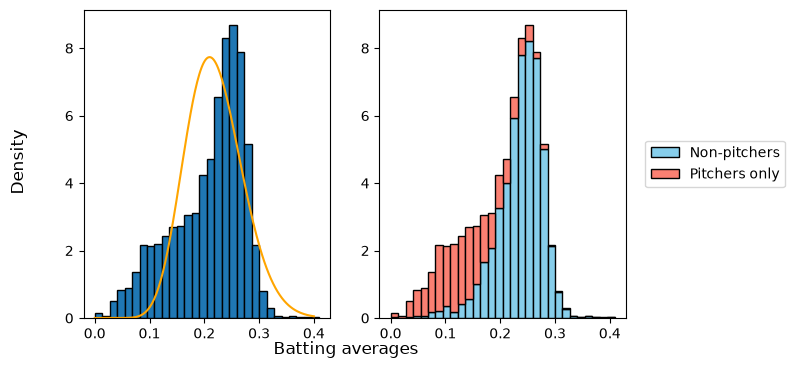

In [4]:
# 8.2.1 · Your code here
fig, axes = plt.subplots(1, 2)

axes[0].hist(fit_data.average, bins = 30, edgecolor = 'black', density = True)

def neg_log_lik(params, H, AB):
    log_a, log_b = params       
    a, b = np.exp(log_a), np.exp(log_b)
    bbsum = stats.betabinom.logpmf(H, AB, a, b).sum()
    return -bbsum             

res = optimize.minimize(neg_log_lik, x0=np.log([1, 10]), args=(fit_data.H, fit_data.AB), method="Nelder-Mead")
a0, b0 = np.exp(res.x)

x = np.linspace(0, 0.4, 200)

axes[0].plot(x, stats.beta(a0, b0).pdf(x), label = f"Fit beta distribution, B({a0}, {b0})", color = 'orange')

colors = ['skyblue', 'salmon']
labels = ['Non-pitchers', 'Pitchers only']
axes[1].hist([fit_data[~fit_data.is_pitcher].average, fit_data[fit_data.is_pitcher].average], bins=30, color=colors, label=labels, stacked=True, edgecolor='black', density = True)

fig.supxlabel("Batting averages")
fig.supylabel("Density")
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show()



## 3. A beta-binomial fitting function

**8.3.1 · Your turn.** Write `fit_bb_mle(H, AB, weights=None)` returning `(alpha, beta)` by maximum likelihood. You've done this in Lesson 02; now wrap it as a reusable function. (`weights` are for the exercise; let them default to 1.)

In [5]:
# 8.3.1 · Your code here
def fit_bb_mle(H, AB, weights = None):
    def neg_log_lik(params):
        log_a, log_b = params       
        a, b = np.exp(log_a), np.exp(log_b)
        bbsum = stats.betabinom.logpmf(H, AB, a, b).sum()
        return -bbsum             

    res = optimize.minimize(neg_log_lik, x0=np.log([1, 10]), method="Nelder-Mead")
    alpha0, beta0 = np.exp(res.x)
    return alpha0, beta0

a_test, b_test = fit_bb_mle(fit_data.H, fit_data.AB)
a_test, b_test

(np.float64(13.815669374693087), np.float64(49.31476357137724))

> **Check:** on all players with AB ≥ 20: α ≈ 12.8, β ≈ 45.5.

## 4. EM by hand: maximize, expect, repeat

We don't know the clusters *or* their parameters. EM alternates:

- **M-step (maximize):** given the cluster assignments, fit a beta-binomial to each cluster.
- **E-step (expect):** given the fitted clusters, compute each player's likelihood under each one (`stats.betabinom.pmf`) and assign him to the more likely cluster.

The book uses *hard* assignments, the most likely cluster. Start from random assignments.

**8.4.1 · Your turn.** Randomly assign each player to cluster A or B (seed your generator), then run one M-step. Plot the two fitted densities over the histogram.

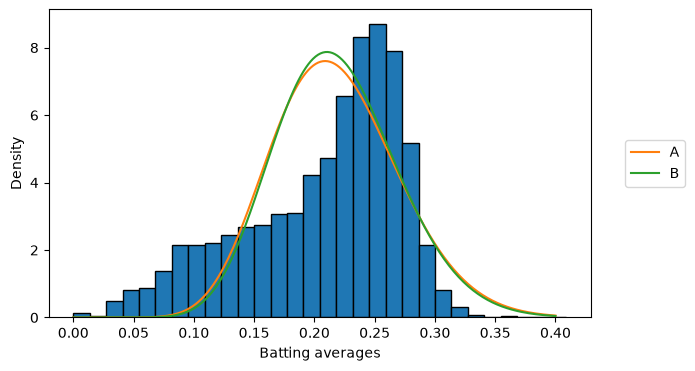

In [6]:
# 8.4.1 · Your code here
clusters = ['A', 'B']
fit_data['cluster'] = rng.choice(clusters, len(fit_data))
fit_data.head()

plt.hist(fit_data.average, bins = 30, edgecolor = 'black', density = True)

alphabetas = {}
for cluster in clusters:
    group = fit_data[fit_data['cluster'] == cluster]
    alphabetas[cluster] =  fit_bb_mle(group.H, group.AB)
    a_fit, b_fit, = alphabetas[cluster]
    plt.plot(x, stats.beta(a_fit, b_fit).pdf(x), label = cluster)
    
plt.xlabel("Batting averages")
plt.ylabel("Density")
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show()

**8.4.2 · Your turn.** Run one E-step. Look at Jeff Abbott (11/42) and Kyle Abbott (3/31): which cluster does each go to?

In [7]:
# 8.4.2 · Your code here
fit_data['cluster'] = np.where(
                            (stats.betabinom.pmf(fit_data.H, fit_data.AB, *alphabetas['A'])) > 
                            (stats.betabinom.pmf(fit_data.H, fit_data.AB, *alphabetas['B'])), 
                            "A", "B")

fit_data[fit_data.name == 'Jeff Abbott'], fit_data[fit_data.name == 'Kyle Abbott']

(    playerID         name   H  AB  average    year  is_pitcher cluster
 5  abbotje01  Jeff Abbott  11  42   0.2619  2001.0       False       B,
     playerID         name  H  AB  average    year  is_pitcher cluster
 8  abbotky01  Kyle Abbott  3  31   0.0968  1993.5        True       A)

**8.4.3 · Your turn.** Wrap both steps in a loop for 10 iterations. Store the parameters and cluster sizes at every iteration, and print progress as it runs (iteration, α and β for each cluster, players that changed cluster).

In [8]:
# 8.4.3 · Your code here

def max_step(df):
    alphabetas = {}
    for c in ["A", "B"]:           
        group = df[df['cluster'] == c]             # Specifying group, to make things more readable
        alphabetas[c] =  fit_bb_mle(group.H, group.AB)   # Maximization step
    return alphabetas
    
def exp_step(df, alphabetas):
    like_A = stats.betabinom.pmf(df.H, df.AB, *alphabetas["A"])
    like_B = stats.betabinom.pmf(df.H, df.AB, *alphabetas["B"])
    return pd.Series(np.where(like_A > like_B, "A", "B"), index=df.index)

def record(df, i, alphabetas, changed):
    row = {"iteration": i, "changed": changed}
    for c in ["A", "B"]:
        row[f"alpha_{c}"], row[f"beta_{c}"] = alphabetas[c]
        row[f"n_{c}"] = (df.cluster == c).sum()
    return row

#First iteration 0:
fit_data['cluster'] = rng.choice(clusters, len(fit_data))   # To re-randomize data in case this cell is run multiple times
ABs = max_step(fit_data)
EM_history = [record(fit_data, 0, ABs, 0)]
assignments = {0: fit_data.cluster.copy()}   # iteration number -> labels

#Looping iterations 1-10:
for i in range(1, 11):
    old = fit_data.cluster.copy()
    fit_data['cluster'] = exp_step(fit_data, ABs)
    changed = (fit_data.cluster != old).sum()
    ABs = max_step(fit_data)
    row = record(fit_data, i, ABs, changed)
    EM_history.append(row)
    assignments[i] = fit_data.cluster.copy()
    print(f'''
        Iteration:{i}
        A cluster alpha {row['alpha_A']:.1f} and beta {row['beta_A']:.1f}, n: {row['n_A']}
        B cluster alpha {row['alpha_B']:.1f} and beta {row['beta_B']:.1f}, n: {row['n_B']}
        Number changed: {changed}''')

history = pd.DataFrame(EM_history)


        Iteration:1
        A cluster alpha 4.8 and beta 17.2, n: 1490
        B cluster alpha 100.9 and beta 351.3, n: 2684
        Number changed: 2016

        Iteration:2
        A cluster alpha 4.2 and beta 17.9, n: 1662
        B cluster alpha 501.9 and beta 1593.3, n: 2512
        Number changed: 794

        Iteration:3
        A cluster alpha 4.8 and beta 22.6, n: 1754
        B cluster alpha 689.6 and beta 2105.3, n: 2420
        Number changed: 542

        Iteration:4
        A cluster alpha 5.5 and beta 27.2, n: 1751
        B cluster alpha 520.9 and beta 1554.8, n: 2423
        Number changed: 303

        Iteration:5
        A cluster alpha 6.4 and beta 33.3, n: 1708
        B cluster alpha 367.6 and beta 1080.6, n: 2466
        Number changed: 189

        Iteration:6
        A cluster alpha 8.1 and beta 44.3, n: 1661
        B cluster alpha 265.0 and beta 771.2, n: 2513
        Number changed: 129

        Iteration:7
        A cluster alpha 11.7 and beta 67.1, n: 160

**8.4.4 · Your turn.** Plot the histograms of the assignments at iterations 0, 1, 2, 5 and the last, plus each cluster's α, β and mean across iterations.

In [9]:
history.head()


,iteration,changed,alpha_A,beta_A,n_A,alpha_B,beta_B,n_B
0,0,0,13.3421,47.4359,2066,14.3109,51.2860,2108
1,1,2016,4.8056,17.2456,1490,100.9045,351.2760,2684
2,2,794,4.1879,17.9489,1662,501.9198,1593.3476,2512
3,3,542,4.8367,22.5540,1754,689.6431,2105.3030,2420
4,4,303,5.5233,27.2101,1751,520.9124,1554.7680,2423


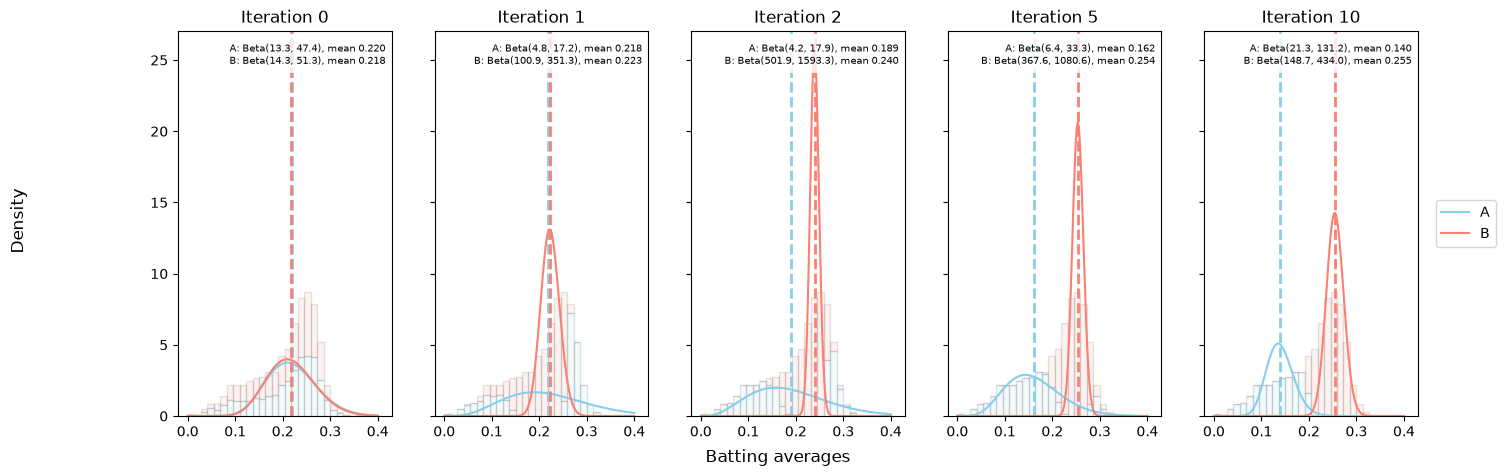

In [10]:
# 8.4.4 · Your code here
fig, axes = plt.subplots(1, 5, figsize = (16, 5), sharey = True)

colors = ['skyblue', 'salmon']

h_row = history.set_index("iteration")
for ax, i, in zip(axes, [0, 1, 2, 5, 10]):
    labels = assignments[i]
    ax.hist([fit_data.average[labels == "A"], fit_data.average[labels == "B"]], 
            stacked = True, color = colors, bins = 30, edgecolor = 'black', density = True, alpha = 0.1)
    
    aA, bA = (h_row.loc[i, "alpha_A"], h_row.loc[i, "beta_A"])
    meanA = (aA / (aA + bA))
    
    aB, bB = (h_row.loc[i, "alpha_B"], h_row.loc[i, "beta_B"])
    meanB = (aB / (aB + bB))
    # print(f"Iteration {i}: {aA}, {bA}, {aB}, {bB}")

    nA, nB = (h_row.loc[i, "n_A"], h_row.loc[i, "n_B"])
    
    ax.plot(x , (nA / (nA + nB))*stats.beta(aA, bA).pdf(x), color = colors[0], label = "A")
    ax.axvline(x = meanA, color= colors[0], linestyle='--', linewidth=2)
    
    ax.plot(x, (nB / (nA + nB))*stats.beta(aB, bB).pdf(x), color = colors[1], label = "B")
    ax.axvline(x = meanB, color= colors[1], linestyle='--', linewidth=2)
    
    ax.set_title(f"Iteration {i}", loc='center')
    txt = (f"A: Beta({aA:.1f}, {bA:.1f}), mean {meanA:.3f}\n"
       f"B: Beta({aB:.1f}, {bB:.1f}), mean {meanB:.3f}")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
        ha="right", va="top", fontsize=7,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
fig.supxlabel("Batting averages")
fig.supylabel("Density")
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show()

> **Check:** the clusters settle near Beta(27, 170) (mean ≈ 0.14, the pitchers) and Beta(145, 419) (mean ≈ 0.26). Which label lands on which group depends on your random start.

## 5. Posterior cluster probabilities

By Bayes' theorem (with equal prior weight on each cluster for now):

$$\Pr(A \mid H, AB) = \frac{L_A}{L_A + L_B}.$$

**8.5.1 · Your turn.** For the players with exactly AB = 100 (the book has six), plot each one's likelihood under the two clusters as a function of H, and compute Pr(pitcher cluster).

In [39]:
# 8.5.1 · Your code here
career_100 = career[career.AB == 100]
aA_final, bA_final = (history.iloc[-1].alpha_A, history.iloc[-1].beta_A)
aB_final, bB_final = (history.iloc[-1].alpha_B, history.iloc[-1].beta_B)

career_100

,playerID,name,H,AB,average,year,is_pitcher
789,buschmi01,Mike Busch,22,100,0.22,1995.5000,False
861,cancero01,Robinson Cancel,20,100,0.20,2006.7500,False
969,castrwi01,Willi Castro,17,100,0.17,2025.0000,True
1362,dejesjo01,Jose de Jesus,11,100,0.11,1990.5000,True
1958,gausmke01,Kevin Gausman,12,100,0.12,2019.3333,True
1985,gilbedr01,Drew Gilbert,19,100,0.19,2025.0000,False
3354,mahonmi02,Mike Mahoney,18,100,0.18,2002.3333,False
5132,shealry01,Ryan Shealy,32,100,0.32,2005.5000,False
5698,uriasju01,Julio Urias,19,100,0.19,2018.2000,True


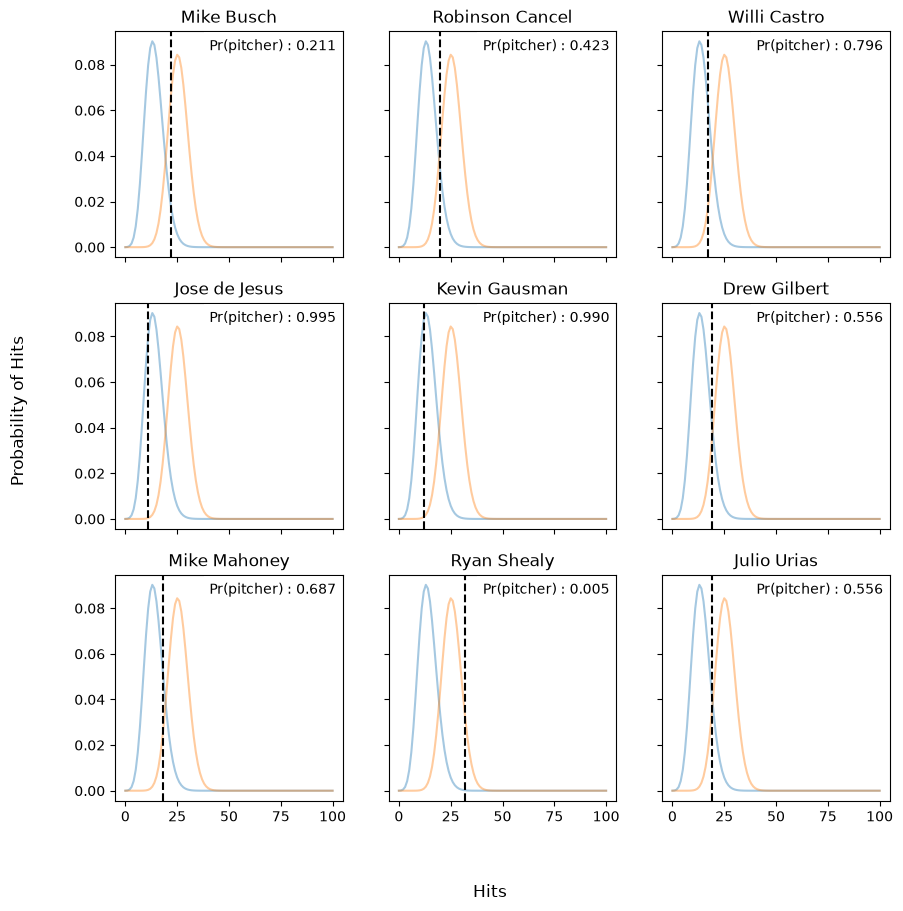

In [45]:
fig, axes = plt.subplots(3, 3, figsize = (10, 10), sharex = True, sharey = True)

H = np.arange(0, 101)

for plyr in range(len(career_100)):
    hits = career_100.iloc[plyr].H
    ax = axes.flat[plyr]
    ax.plot(H, stats.betabinom.pmf(H, 100, aA_final, bA_final), alpha = 0.4)
    ax.plot(H, stats.betabinom.pmf(H, 100, aB_final, bB_final), alpha = 0.4)
    ax.axvline(x = hits, linestyle = '--', color = 'black')
    ax.set_title(career_100.iloc[plyr]['name'], loc = 'center')
    LA = stats.betabinom.pmf(hits, 100, aA_final, bA_final).sum()
    LB = stats.betabinom.pmf(hits, 100, aB_final, bB_final).sum()
    pA = (LA / (LA + LB))
    txt = (f"Pr(pitcher) : {pA:.3f}\n")
    ax.text(0.97, 0.97, txt, transform=ax.transAxes,
        ha="right", va="top", fontsize=10,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
fig.supxlabel("Hits")
fig.supylabel("Probability of Hits")
plt.show()

**8.5.2 · Your turn.** Compute the posterior cluster probability for every player with AB > 20.

In [50]:
# 8.5.2 · Your code here
fit_data["Lpitcher"] = stats.betabinom.pmf(fit_data.H, fit_data.AB, aA_final, bA_final)
fit_data["Lnotpitcher"] = stats.betabinom.pmf(fit_data.H, fit_data.AB, aB_final, bB_final)
fit_data["Ppitcher"] = (fit_data.Lpitcher / (fit_data.Lpitcher + fit_data.Lnotpitcher))
fit_data.head()

,playerID,name,H,AB,average,year,is_pitcher,cluster,Lpitcher,Lnotpitcher,Ppitcher
5,abbotje01,Jeff Abbott,11,42,0.2619,2001.0,False,B,2.2561e-02,0.1334,0.1447
6,abbotji01,Jim Abbott,2,21,0.0952,1999.0,True,A,2.2844e-01,0.0527,0.8126
7,abbotku01,Kurt Abbott,475,1860,0.2554,1997.5,False,B,1.6123e-05,0.0104,0.0016
8,abbotky01,Kyle Abbott,3,31,0.0968,1993.5,True,A,1.7581e-01,0.0213,0.8918
10,abercre01,Reggie Abercrombie,86,386,0.2228,2007.0,False,B,1.8604e-03,0.0197,0.0863


## 6. How well did it find the pitchers?

**8.6.1 · Your turn.** Keep players whose top cluster probability is at least 0.8, and cross-tabulate assigned cluster against `is_pitcher` (`pd.crosstab`).

In [61]:
# 8.6.1 · Your code here
certain = np.maximum(fit_data.Ppitcher, 1-fit_data.Ppitcher) > 0.8
pd.crosstab(fit_data.cluster[certain], fit_data.is_pitcher[certain])

is_pitcher,False,True
cluster,,
A,165,850
B,2141,99


> **Check:** the book got about 1,697 non-pitchers and 697 pitchers right, with 106 + 55 wrong.

## 7. Shrinkage with a mixture

Each player's posterior is now a *mixture* of two betas, weighted by his cluster probabilities. The posterior mean is still easy, by linearity:

$$\hat p_i = \sum_k \Pr(k \mid \text{data}_i)\, \frac{H_i + \alpha_k}{AB_i + \alpha_k + \beta_k}.$$

**8.7.1 · Your turn.** Compute the mixture-shrunken estimate for every player. Plot it against AB (log x), next to a single-prior estimate.

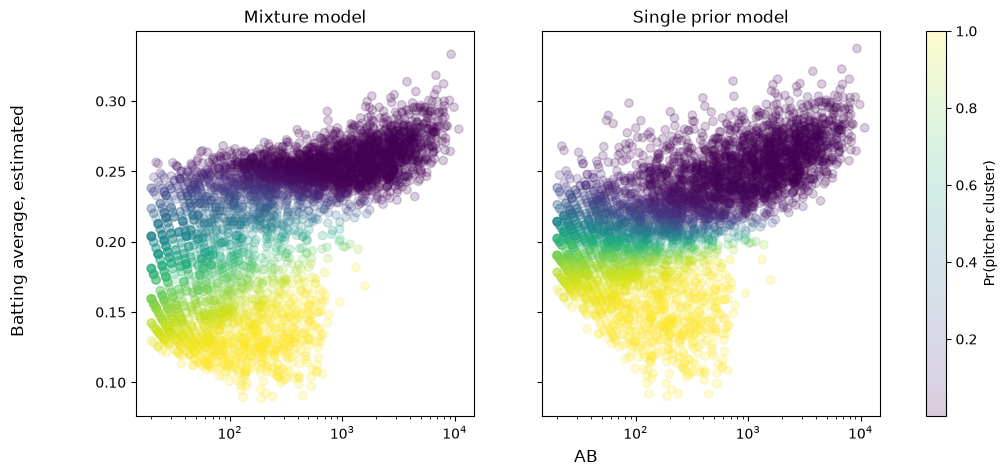

In [95]:
# 8.7.1 · Your code here
fit_data["post_mix"] = (fit_data.Ppitcher * ((aA_final + fit_data.H) / (aA_final + bA_final + fit_data.AB))) + ((1-fit_data.Ppitcher) * ((aB_final + fit_data.H) / (aB_final + bB_final + fit_data.AB)))
fit_data["post_single"] = (a_test + fit_data.H) / (a_test + b_test + fit_data.AB)
fit_data.head()

fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True, sharex = True)
axes[0].scatter(fit_data.AB, fit_data.post_mix, c=fit_data.Ppitcher, alpha = 0.2)
axes[0].set_xscale("log")
axes[0].set_title("Mixture model")

sc = axes[1].scatter(fit_data.AB, fit_data.post_single, c=fit_data.Ppitcher, alpha = 0.2)
axes[1].set_xscale("log")
axes[1].set_title("Single prior model")
fig.colorbar(sc, ax=axes, label="Pr(pitcher cluster)")
fig.supxlabel("AB")
fig.supylabel("Batting average, estimated")
plt.show()

**8.7.2 · Reflect.** Players with intermediate averages barely move. Why? And why is a 95% credible interval awkward for someone whose posterior has two bumps?

*8.7.2 · Your answer:*

## 8. Exercises

**8.8.1 · Your turn.** **Soft EM.** Use the posterior probabilities as weights in the M-step (a weighted log-likelihood), and also estimate the mixing proportions π_A and π_B, using them in the E-step. Does the answer change? Does it converge faster or slower?

In [ ]:
# 8.8.1 · Your code here

**8.8.2 · Your turn.** Try three clusters. What does the third one capture, if anything?

In [ ]:
# 8.8.2 · Your code here

**8.8.3 · Reflect.** **Card connection.** Imagine a dataset of trading-card sales. Most cards are *bulk*: common cards that sell for well under a dollar. A few are *chase* cards, the rare ones collectors hunt for, selling for tens or hundreds of dollars. Separately, a card can be sold *raw* (as it came out of the pack) or *graded* (authenticated, scored for condition from 1 to 10 and sealed in a plastic case by a grading company), which usually raises its price. Where might a mixture show up in that data: bulk cards vs chase cards, raw vs graded listings? What would the clusters mean, and what would you use them for?

*8.8.3 · Your answer:*

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 9.
- Bishop, *Pattern Recognition and Machine Learning* (2006), Chapter 9: mixture models and EM.
- McLachlan & Peel, *Finite Mixture Models* (2000).